# Customer Churn Prediction – Model Training

## Objective
Train and compare three machine learning models to predict customer churn.

## Models
1. Logistic Regression
2. Random Forest
3. XGBoost

In [2]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [3]:
import joblib

prepared_data = joblib.load(
    "../data/processed/prepared_data.pkl"
)

X_train = prepared_data["X_train"]
X_test = prepared_data["X_test"]
y_train = prepared_data["y_train"]
y_test = prepared_data["y_test"]

In [4]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 46)
X_test: (1409, 46)
y_train: (5634,)
y_test: (1409,)


In [5]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [6]:
logistic_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [7]:
y_pred = logistic_model.predict(X_test)

In [8]:
print(y_pred[:20])

[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]


In [9]:
print("Predicted churn:", (y_pred == 1).sum())
print("Predicted no churn:", (y_pred == 0).sum())

Predicted churn: 318
Predicted no churn: 1091


In [10]:
print("Actual customer outcomes:")
print(y_test.value_counts())

print("\nPredicted customer outcomes:")
print(pd.Series(y_pred).value_counts())

Actual customer outcomes:
Churn
0    1035
1     374
Name: count, dtype: int64

Predicted customer outcomes:
0    1091
1     318
Name: count, dtype: int64


In [11]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1 Score: 0.6040462427745664


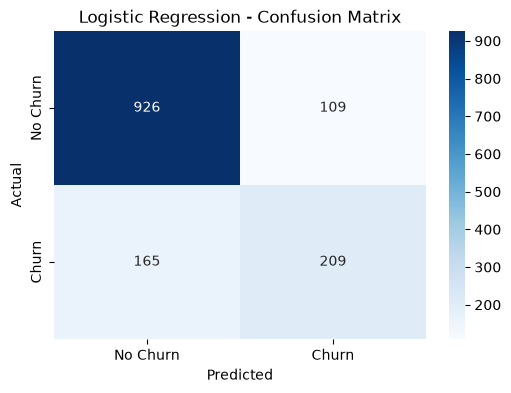

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

## Logistic Regression – Results

- Accuracy: 80.55%
- Precision: 65.72%
- Recall: 55.88%
- F1 Score: 60.40%

### Observation
The model achieved 80.55% accuracy.
However, its recall is 55.88%, meaning it identified
approximately 56% of actual churn customers.

There is room to improve churn detection.

# Random Forest Classifier

In [13]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

In [14]:
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [15]:
y_pred_rf = rf_model.predict(X_test)

In [16]:
print("First 20 predictions:")
print(y_pred_rf[:20])

print("\nPredicted churn:", (y_pred_rf == 1).sum())

print("Predicted no churn:", (y_pred_rf == 0).sum())

First 20 predictions:
[0 1 0 0 0 1 1 0 0 1 0 0 0 1 0 0 0 1 0 0]

Predicted churn: 434
Predicted no churn: 975


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(y_test, y_pred_rf)

rf_recall = recall_score(y_test, y_pred_rf)

rf_f1 = f1_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("--------------------------")

print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1 Score:  {rf_f1:.4f}")

Random Forest Performance
--------------------------
Accuracy:  0.7630
Precision: 0.5461
Recall:    0.6337
F1 Score:  0.5866


In [18]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.86      0.81      0.83      1035
       Churn       0.55      0.63      0.59       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.78      0.76      0.77      1409



In [20]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[838 197]
 [137 237]]


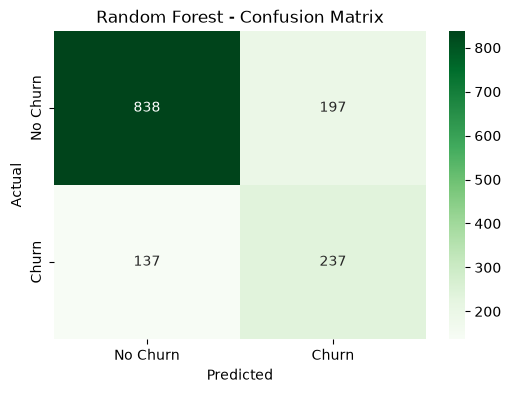

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")

plt.show()

In [24]:
import joblib

preprocessor = joblib.load("../models/preprocessor.pkl")
feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                                Feature  Importance
2                     num__TotalCharges    0.139478
0                           num__tenure    0.129689
1                   num__MonthlyCharges    0.121980
37         cat__Contract_Month-to-month    0.067401
39               cat__Contract_Two year    0.042099
19               cat__OnlineSecurity_No    0.038746
17     cat__InternetService_Fiber optic    0.027550
28                  cat__TechSupport_No    0.026584
44  cat__PaymentMethod_Electronic check    0.025610
22                 cat__OnlineBackup_No    0.020811
3                    cat__gender_Female    0.016458
4                      cat__gender_Male    0.016000
38               cat__Contract_One year    0.015317
41            cat__PaperlessBilling_Yes    0.015089
8                      cat__Partner_Yes    0.013624


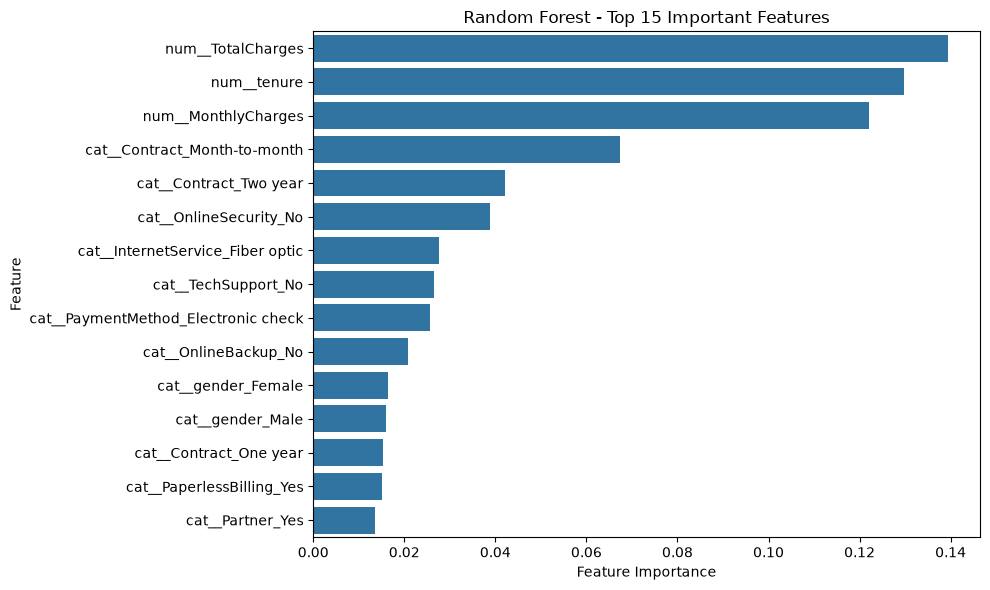

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

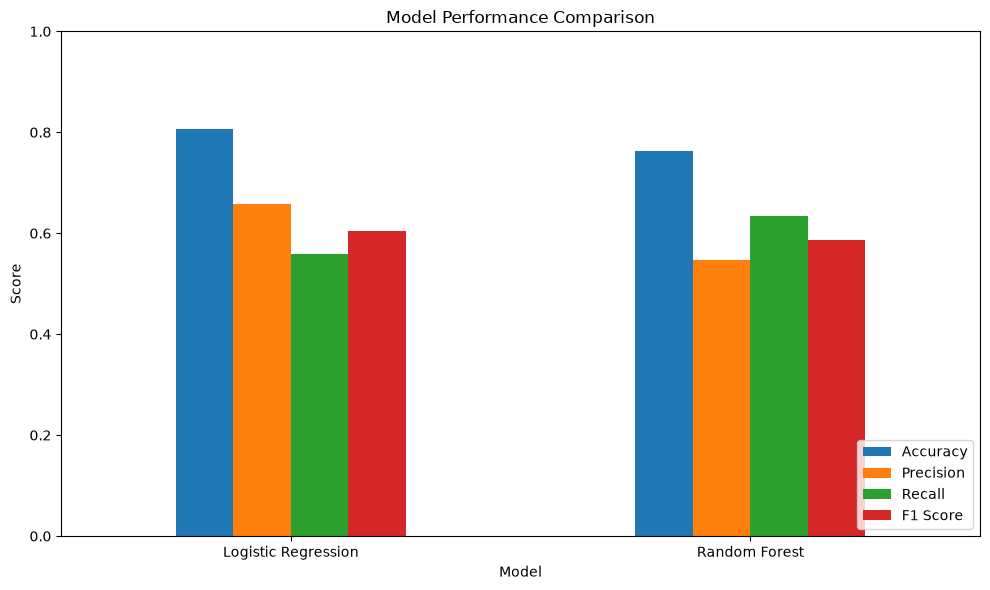

In [26]:
models = ["Logistic Regression", "Random Forest"]

results = pd.DataFrame({
    "Model": models,
    "Accuracy": [accuracy, rf_accuracy],
    "Precision": [precision, rf_precision],
    "Recall": [recall, rf_recall],
    "F1 Score": [f1, rf_f1]
})

results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# XGBoost Classifier

## Objective
Train an XGBoost model to predict customer churn.

## Steps
1. Import XGBoost.
2. Create the model.
3. Train the model.
4. Make predictions.
5. Evaluate model performance.
6. Generate a confusion matrix.
7. Analyze feature importance.

In [27]:
from xgboost import XGBClassifier

In [28]:
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [29]:
xgb_model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [30]:
y_pred_xgb = xgb_model.predict(X_test)

In [31]:
print("First 20 predictions:")
print(y_pred_xgb[:20])

print("\nPredicted churn:", (y_pred_xgb == 1).sum())

print("Predicted no churn:", (y_pred_xgb == 0).sum())

First 20 predictions:
[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]

Predicted churn: 308
Predicted no churn: 1101


In [32]:
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

xgb_precision = precision_score(y_test, y_pred_xgb)

xgb_recall = recall_score(y_test, y_pred_xgb)

xgb_f1 = f1_score(y_test, y_pred_xgb)

print("XGBoost Performance")
print("-------------------")

print(f"Accuracy:  {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall:    {xgb_recall:.4f}")
print(f"F1 Score:  {xgb_f1:.4f}")

XGBoost Performance
-------------------
Accuracy:  0.8013
Precision: 0.6526
Recall:    0.5374
F1 Score:  0.5894


In [33]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.65      0.54      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [34]:
from sklearn.metrics import confusion_matrix

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

print(cm_xgb)

[[928 107]
 [173 201]]


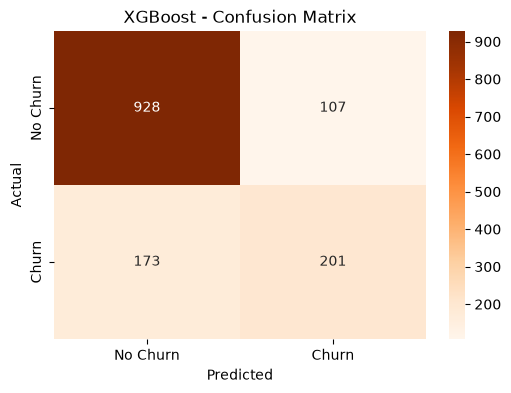

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost - Confusion Matrix")

plt.show()

In [36]:
preprocessor = joblib.load("../models/preprocessor.pkl")

feature_importance_xgb = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": xgb_model.feature_importances_
})

feature_importance_xgb = feature_importance_xgb.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_xgb.head(15))

                                    Feature  Importance
37             cat__Contract_Month-to-month    0.343797
17         cat__InternetService_Fiber optic    0.077536
19                   cat__OnlineSecurity_No    0.066519
20  cat__OnlineSecurity_No internet service    0.065591
16                 cat__InternetService_DSL    0.046470
39                   cat__Contract_Two year    0.035602
28                      cat__TechSupport_No    0.031778
44      cat__PaymentMethod_Electronic check    0.020636
36                 cat__StreamingMovies_Yes    0.018002
38                   cat__Contract_One year    0.016044
0                               num__tenure    0.014827
18                  cat__InternetService_No    0.014081
40                 cat__PaperlessBilling_No    0.012978
13                    cat__MultipleLines_No    0.012867
41                cat__PaperlessBilling_Yes    0.012846


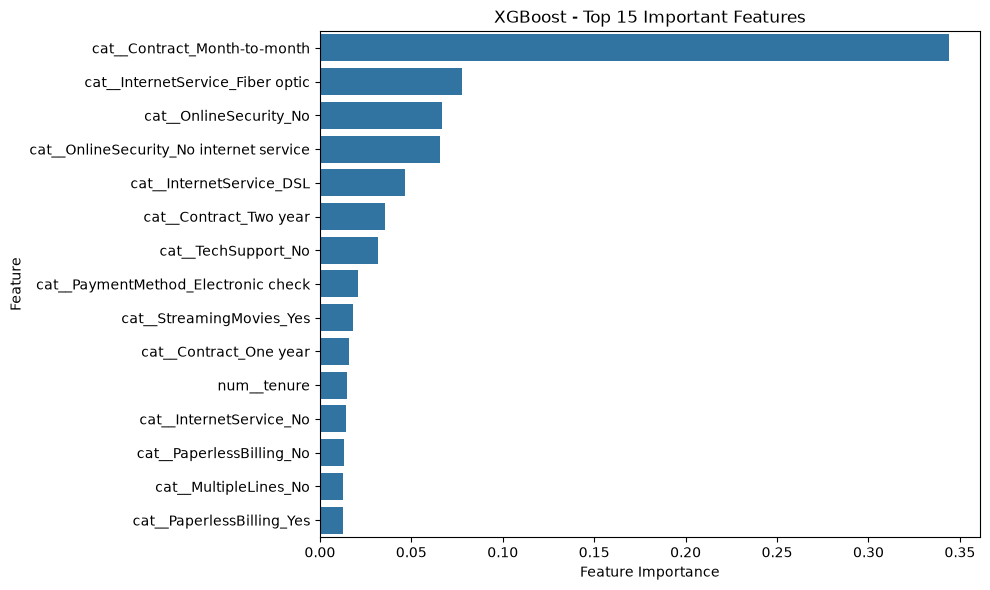

In [37]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_xgb.head(15),
    x="Importance",
    y="Feature"
)

plt.title("XGBoost - Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [38]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy,
        rf_accuracy,
        xgb_accuracy
    ],

    "Precision": [
        precision,
        rf_precision,
        xgb_precision
    ],

    "Recall": [
        recall,
        rf_recall,
        xgb_recall
    ],

    "F1 Score": [
        f1,
        rf_f1,
        xgb_f1
    ]
})

print(model_comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.8055     0.6572  0.5588    0.6040
1        Random Forest    0.7630     0.5461  0.6337    0.5866
2              XGBoost    0.8013     0.6526  0.5374    0.5894


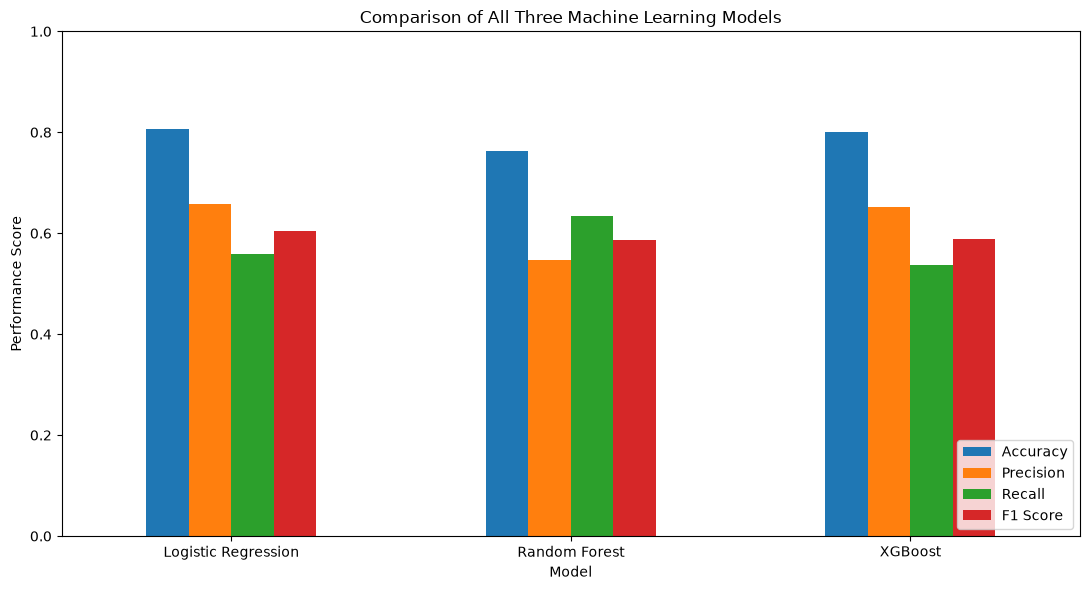

In [39]:
model_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of All Three Machine Learning Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

## Hyperparameter Tuning – Random Forest

We will test different Random Forest settings using cross-validation
to improve the model's ability to identify customers who churn.

In [40]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [41]:
param_dist = {
    "n_estimators": randint(100, 500),
    "max_depth": [None, 5, 10, 15, 20, 30],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 10),
    "max_features": ["sqrt", "log2"],
    "class_weight": [None, "balanced", "balanced_subsample"]
}

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_dist,
    n_iter=30,
    scoring="recall",
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [43]:
rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'class_weight': [None, 'balanced', ...], 'max_depth': [None, 5, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': <scipy.stats....t 0x11e048b90>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can 

In [44]:
print("Best Parameters:")
print(rf_search.best_params_)

Best Parameters:
{'class_weight': 'balanced', 'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 3, 'min_samples_split': 8, 'n_estimators': 340}


In [45]:
best_rf_model = rf_search.best_estimator_

print("Best Cross-Validation Recall:")
print(rf_search.best_score_)

Best Cross-Validation Recall:
0.8006688963210703


In [46]:
best_rf_model = rf_search.best_estimator_

print("Best Parameters:")
print(rf_search.best_params_)

print("\nBest Cross-Validation Recall:")
print(round(rf_search.best_score_, 4))

Best Parameters:
{'class_weight': 'balanced', 'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 3, 'min_samples_split': 8, 'n_estimators': 340}

Best Cross-Validation Recall:
0.8007


In [47]:
y_pred_tuned_rf = best_rf_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [48]:
import pandas as pd

prediction_counts = pd.Series(
    y_pred_tuned_rf
).value_counts()

print(prediction_counts)

0    819
1    590
Name: count, dtype: int64


In [49]:
tuned_accuracy = accuracy_score(y_test, y_pred_tuned_rf)

tuned_precision = precision_score(
    y_test, y_pred_tuned_rf
)

tuned_recall = recall_score(
    y_test, y_pred_tuned_rf
)

tuned_f1 = f1_score(
    y_test, y_pred_tuned_rf
)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("Accuracy: ", round(tuned_accuracy, 4))
print("Precision:", round(tuned_precision, 4))
print("Recall:   ", round(tuned_recall, 4))
print("F1 Score: ", round(tuned_f1, 4))

Tuned Random Forest Performance
--------------------------------
Accuracy:  0.7317
Precision: 0.4966
Recall:    0.7834
F1 Score:  0.6079


In [50]:
print(
    classification_report(
        y_test,
        y_pred_tuned_rf,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.90      0.71      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.79      0.73      0.75      1409



In [51]:
from sklearn.metrics import confusion_matrix

cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned_rf
)

print("Confusion Matrix:")
print(cm_tuned)

Confusion Matrix:
[[738 297]
 [ 81 293]]


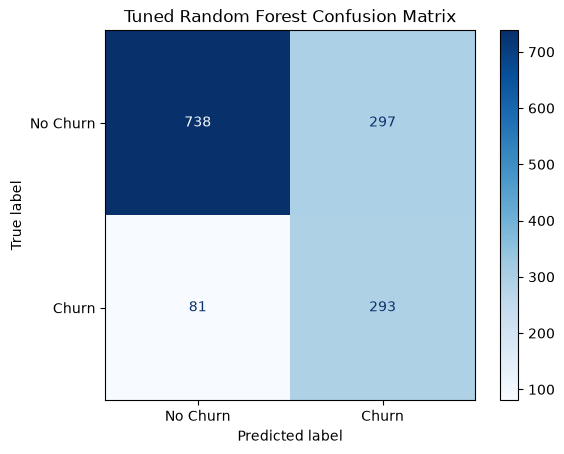

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["No Churn", "Churn"]
)

cm_display.plot(cmap="Blues")

plt.title("Tuned Random Forest Confusion Matrix")
plt.show()

In [53]:
y_pred_lr = logistic_model.predict(X_test)

y_pred_rf = rf_model.predict(X_test)

y_pred_xgb = xgb_model.predict(X_test)

y_pred_tuned_rf = best_rf_model.predict(X_test)

In [54]:
models_predictions = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "Tuned Random Forest": y_pred_tuned_rf
}

In [55]:
results = []

for model_name, predictions in models_predictions.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

model_comparison = pd.DataFrame(results)

print(model_comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.8055     0.6572  0.5588    0.6040
1        Random Forest    0.7630     0.5461  0.6337    0.5866
2              XGBoost    0.8013     0.6526  0.5374    0.5894
3  Tuned Random Forest    0.7317     0.4966  0.7834    0.6079


In [56]:
best_model_name = (
    model_comparison
    .sort_values(
        by=["Recall", "F1 Score"],
        ascending=False
    )
    .iloc[0]["Model"]
)

model_objects = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "Tuned Random Forest": best_rf_model
}

final_model = model_objects[best_model_name]

print("Selected Final Model:")
print(best_model_name)

Selected Final Model:
Tuned Random Forest


In [57]:
import joblib

from sklearn.pipeline import Pipeline

In [58]:
preprocessor = joblib.load(
    "../models/preprocessor.pkl"
)

print("Preprocessor loaded successfully!")

Preprocessor loaded successfully!


In [59]:
final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", final_model)
])

print("Final pipeline created successfully!")

Final pipeline created successfully!


In [60]:
joblib.dump(
    final_pipeline,
    "../models/final_churn_pipeline.pkl"
)

print("Final pipeline saved successfully!")

Final pipeline saved successfully!


In [61]:
saved_model = joblib.load(
    "../models/final_churn_pipeline.pkl"
)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [63]:
test_customer = X_test[[0]]

print(test_customer)

[[1.60848343 1.62997635 2.70682752 0.         1.         1.
  0.         0.         1.         0.         1.         0.
  1.         0.         0.         1.         0.         1.
  0.         0.         0.         1.         0.         0.
  1.         0.         0.         1.         0.         0.
  1.         0.         0.         1.         0.         0.
  1.         0.         0.         1.         0.         1.
  0.         1.         0.         0.        ]]


In [64]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/cleaned_customer_churn.csv"
)

X_raw = df.drop(
    columns=["customerID", "Churn"]
)

test_customer = X_raw.iloc[[0]]

print(test_customer)

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   

  PaperlessBilling     PaymentMethod  MonthlyCharges  TotalCharges  
0              Yes  Electronic check           29.85         29.85  


In [65]:
test_prediction = saved_model.predict(test_customer)

print("Predicted Churn:", test_prediction[0])

if test_prediction[0] == 1:
    print("Customer is likely to churn.")
else:
    print("Customer is likely to stay.")

Predicted Churn: 1
Customer is likely to churn.


In [66]:
test_probability = saved_model.predict_proba(test_customer)

classifier = saved_model.named_steps["classifier"]

churn_index = list(classifier.classes_).index(1)

churn_probability = test_probability[0][churn_index]

print(
    "Churn Probability:",
    round(churn_probability * 100, 2),
    "%"
)

Churn Probability: 70.25 %
